# Physics-Informed Neural Networks


### Setup and notation

A PINN is a neural function $u_\theta$ trained using a governing equation as well as initial/boundary information. Here $t$ denotes physical time, and $x,y$ denote spatial coordinates.

**Data requirements:** No simulation dataset is needed for the forward examples: initial and boundary conditions are computed from known formulas, while collocation points need no solution labels.

In [35]:
import math
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(4)
np.random.seed(4)
torch.set_num_threads(2)
DEVICE = torch.device('cpu')
PI = math.pi
print('PyTorch:', torch.__version__, '| Device:', DEVICE)

PyTorch: 2.14.1 | Device: cpu


In [36]:
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim=1, width=32, depth=3):
        super().__init__()
        layers = []
        sizes = [input_dim] + [width] * depth + [output_dim]
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i+1]))
            if i < len(sizes) - 2:
                layers.append(nn.Tanh())  # Smooth activation for PDE derivatives
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)

"""
NB: torch.autograd.grad(y, x, grad_outputs) = grad_outputs^T @ dy_dx

Example: 
x.shape = (100, 2)   # 100 points, coordinates (t, x)
y.shape = (100, 1)   # scalar output  u(t,x)

dy_dx.shape = (100, 2)
u_t = dy_dx[:, 0:1]  # (100, 1)
u_x = dy_dx[:, 1:2]  # (100, 1)


create_graph=True 
builds a computational graph for the gradient itself,
allowing further differentiation (e.g., computing u_xx from u_x)
and backpropagation through derivatives.
"""

def grad(y, x):
    """Differentiate scalar-output y w.r.t. its input x (batchwise)."""
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y),
                               create_graph=True)[0]


def fit(model, loss_fn, steps=500, lr=1e-3, print_every=100):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for step in range(steps):
        optimizer.zero_grad()
        loss = loss_fn()
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
        if (step + 1) % print_every == 0:
            print(f'step {step+1:4d} | loss {history[-1]:.5f}')
    return history

## 1. A PINN from scratch: 1D heat equation

We solve

$$u_t-\kappa u_{xx}=0,\qquad (t,x)\in[0,1]\times[0,1],\qquad \kappa=0.1.$$

With $u(0,x)=\sin(\pi x)$ and $u(t,0)=u(t,1)=0$, the exact solution is

$$u(t,x)=e^{-\kappa\pi^2t}\sin(\pi x).$$

Our NN is $(t,x)\mapsto u_\theta(t,x)$. A **standard soft-constraint PINN** minimizes

$$ L =L_{\mathrm{PDE}}+\lambda_{\mathrm{IC}}L_{\mathrm{IC}}+\lambda_{\mathrm{BC}}L_{\mathrm{BC}},$$

where $ R_\theta=u_{\theta,t}-\kappa u_{\theta,xx}$. All three losses use independent sampled points.

In [37]:
KAPPA = 0.1
heat = MLP(input_dim=2, width=32, depth=3).to(DEVICE)

def heat_exact(tx):
    t, x = tx[:, :1], tx[:, 1:2]
    return torch.exp(-KAPPA * PI**2 * t) * torch.sin(PI*x)

# physics-informed neural network (PINN) for the 1D heat equation
def heat_residual(model, tx):
    tx = tx.detach().requires_grad_(True)
    u = model(tx)
    d = grad(u, tx)
    u_t, u_x = d[:, :1], d[:, 1:2]
    u_xx = grad(u_x, tx)[:, 1:2]
    return u_t - KAPPA*u_xx

def heat_losses(model, n_r=80, n_ic=40, n_bc=40):

    # physics-informed loss over collocation points tx_r
    tx_r = torch.rand(n_r, 2, device=DEVICE)
    r = heat_residual(model, tx_r)
    L_pde = (r**2).mean()

    # initial condition loss
    x_ic = torch.rand(n_ic,1,device=DEVICE)
    tx_ic = torch.cat([torch.zeros_like(x_ic),x_ic],dim=1)
    obs_ic = torch.sin(PI*x_ic) # if the initial condition function is unknown we cannot sample from it, but we can use a few orservarions to enforce the initial condition
    pred_ic = model(tx_ic)
    L_ic = ((pred_ic-obs_ic)**2).mean()

    # boundary condition loss
    t_bc = torch.rand(n_bc,1,device=DEVICE)
    tx_left = torch.cat([t_bc,torch.zeros_like(t_bc)],dim=1)
    tx_right = torch.cat([t_bc,torch.ones_like(t_bc)],dim=1)
    L_bc = (model(tx_left)**2).mean()+(model(tx_right)**2).mean() # solution u(t,0)=u(t,1)=0
    return L_pde, L_ic, L_bc

def standard_heat_objective():
    pde, ic, bc = heat_losses(heat)
    return pde + 10*ic + 10*bc  # weighting initial and boundary conditions more heavily

heat_history = fit(heat, standard_heat_objective, steps=1000, print_every=50)

step   50 | loss 2.45894
step  100 | loss 2.15499
step  150 | loss 1.21729
step  200 | loss 0.40348
step  250 | loss 0.14388
step  300 | loss 0.05100
step  350 | loss 0.03239
step  400 | loss 0.01840
step  450 | loss 0.01741
step  500 | loss 0.01395
step  550 | loss 0.00794
step  600 | loss 0.00684
step  650 | loss 0.00278
step  700 | loss 0.00369
step  750 | loss 0.00263
step  800 | loss 0.00320
step  850 | loss 0.00297
step  900 | loss 0.00192
step  950 | loss 0.00250
step 1000 | loss 0.00316


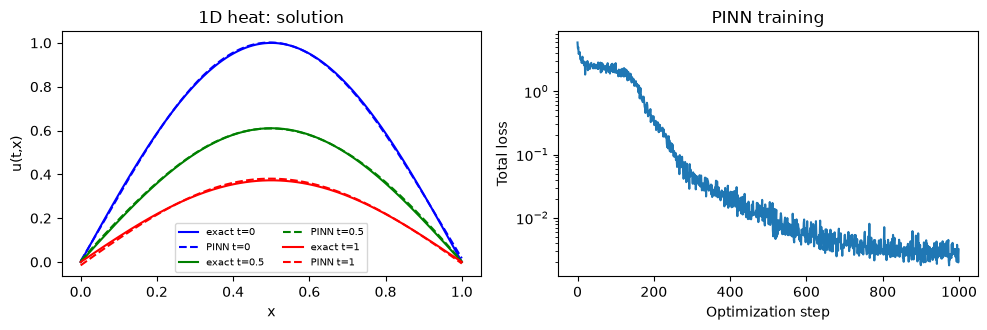

Mean absolute test error: 0.0029626889154314995


In [38]:
x = torch.linspace(0,1,200).reshape(-1,1)
c = ['b', 'g', 'r']
fig, axes = plt.subplots(1,2,figsize=(10,3.4))
with torch.no_grad():
    for i, time in enumerate((0.,0.5,1.)):
        tx = torch.cat([torch.full_like(x,time),x],dim=1)
        axes[0].plot(x.numpy(),heat_exact(tx).numpy(),label=f'exact t={time:g}', color=c[i])
        axes[0].plot(x.numpy(),heat(tx).numpy(),'--',label=f'PINN t={time:g}', color=c[i])
axes[0].set(xlabel='x',ylabel='u(t,x)',title='1D heat: solution')
axes[0].legend(fontsize=7,ncol=2)
axes[1].semilogy(heat_history)
axes[1].set(xlabel='Optimization step',ylabel='Total loss',title='PINN training')
fig.tight_layout(); plt.show()
with torch.no_grad():
    tx = torch.rand(1000,2)
    print('Mean absolute test error:', (heat(tx)-heat_exact(tx)).abs().mean().item())

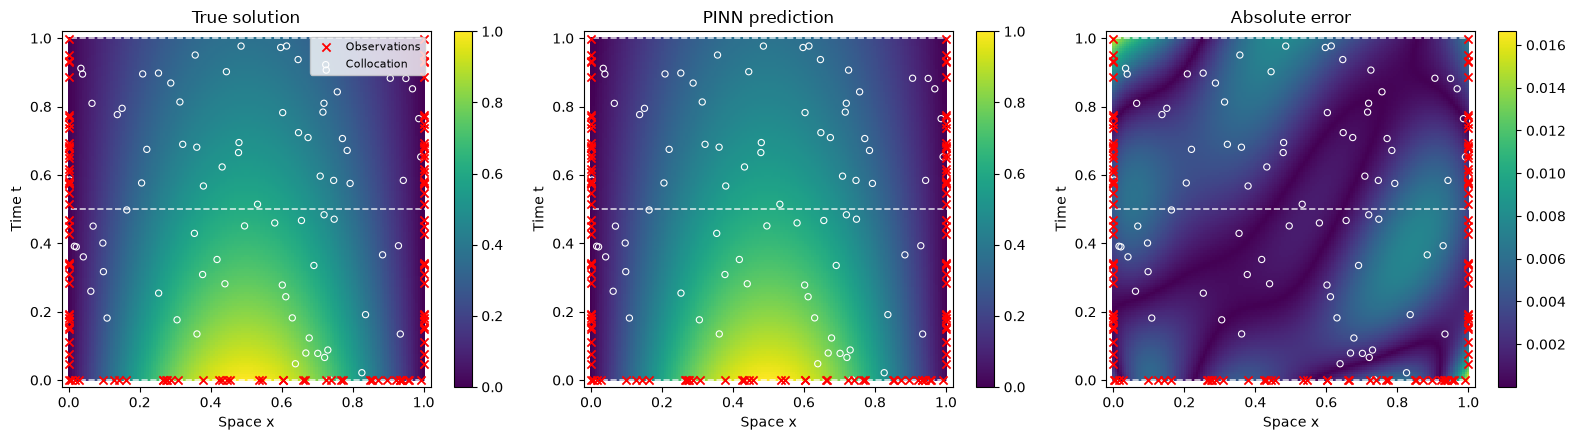

In [39]:
# Generate representative training points
n_r, n_ic, n_bc = 80, 40, 40
device = next(heat.parameters()).device

# PDE collocation points
X_col = torch.rand(n_r, 2, device=device)

# Initial condition: t = 0
x_ic = torch.rand(n_ic, 1, device=device)
X_ic = torch.cat([torch.zeros_like(x_ic), x_ic], dim=1)

# Boundary conditions: x = 0 and x = 1
t_bc = torch.rand(n_bc, 1, device=device)
X_left = torch.cat([t_bc, torch.zeros_like(t_bc)], dim=1)
X_right = torch.cat([t_bc, torch.ones_like(t_bc)], dim=1)

# All constrained points
X_obs = torch.cat([X_ic, X_left, X_right], dim=0)

obs = X_obs.detach().cpu().numpy()
col = X_col.detach().cpu().numpy()

# Evaluation grid
t = np.linspace(0, 1, 150)
x = np.linspace(0, 1, 150)
T, X = np.meshgrid(t, x, indexing="ij")

TX = torch.tensor(
    np.column_stack([T.ravel(), X.ravel()]),
    dtype=torch.float32,
    device=device
)

# PINN prediction
heat.eval()
with torch.no_grad():
    U_pred = heat(TX).cpu().numpy().reshape(T.shape)

# Analytical solution and error
U_true = np.exp(-KAPPA * np.pi**2 * T) * np.sin(np.pi * X)
U_error = np.abs(U_true - U_pred)

# Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, (ax, U, title) in enumerate(zip(
    axes,
    [U_true, U_pred, U_error],
    ["True solution", "PINN prediction", "Absolute error"]
)):
    im = ax.pcolormesh(
        x, t, U, shading="auto", cmap="viridis",
        vmin=0 if i < 2 else None,
        vmax=1 if i < 2 else None
    )

    # Reference times
    for t_line in [0, 0.5, 1]:
        ax.axhline(t_line, color="white", linestyle="--",
                   linewidth=1.2, alpha=0.8)

    # Observations (initial and boundary conditions)
    ax.scatter(
        obs[:, 1], obs[:, 0],
        marker="x", color="red", s=35,
        linewidths=1.3, label="Observations", zorder=5
    )

    # PDE collocation points
    ax.scatter(
        col[:, 1], col[:, 0],
        marker="o", facecolors="none", edgecolors="white",
        s=20, linewidths=0.8, label="Collocation", zorder=4
    )

    ax.set_xlabel("Space x")
    ax.set_ylabel("Time t")
    ax.set_title(title)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)

    fig.colorbar(im, ax=ax)

axes[0].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

### What just happened?

- The initial condition provides labels **only at $t=0$**.
- Boundary labels are available at $x=0$ and $x=1$.
- The PDE collocation points $(t,x)$ are **unlabelled**; automatic differentiation computes $u_t$ and $u_{xx}$.
- The predicted field approximates the solution over the **entire** time interval.

**Try:** change `KAPPA` consistently in both the PDE and the exact solution; or remove the IC loss and observe the failure mode.

## 2. Two spatial dimensions: the Poisson equation

Now $(x,y)\in[0,1]^2$ and we solve the **stationary** problem

$$-\Delta u = - (u_{xx}+u_{yy})=f(x,y),\qquad u\vert_{\partial\Omega}=0.$$

We now consider a non-zero forcing term $f(x,y)$.
Pick the manufactured exact solution

$$u(x,y)=\sin(\pi x)\sin(\pi y),\quad f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y).$$

The PDE residual is $ R_\theta=-u_{\theta,xx}-u_{\theta,yy}-f$. This example illustrates the multidimensional Laplacian without the extra complexity of physical time.

In [40]:
poisson = MLP(input_dim=2, width=32, depth=3)

def poisson_exact(xy):
    return torch.sin(PI*xy[:, :1])*torch.sin(PI*xy[:, 1:2])

# PINN for the 2D Poisson equation
def poisson_residual(model, xy):
    xy = xy.detach().requires_grad_(True)
    u = model(xy)
    first = grad(u,xy)
    u_xx = grad(first[:, :1],xy)[:, :1]
    u_yy = grad(first[:, 1:2],xy)[:, 1:2]
    f = 2*PI**2*poisson_exact(xy)
    return -u_xx-u_yy-f

def sample_boundary(n):
    edge = torch.randint(0,4,(n,))
    xy = torch.cat([torch.rand(n,1),torch.rand(n,1)],dim=1) # (n,2)

    # project points onto the boundary of the unit square
    xy[edge==0,0]=0; xy[edge==1,0]=1 
    xy[edge==2,1]=0; xy[edge==3,1]=1
    return xy

def poisson_objective():
    r = poisson_residual(poisson, torch.rand(100,2)) # torch.rand(100,2) collocation points for PDE residual
    bc = poisson(sample_boundary(60))
    return (r**2).mean()+30*(bc**2).mean()

poisson_history = fit(poisson,poisson_objective,steps=1000,lr=1e-3,print_every=75)

step   75 | loss 23.26509
step  150 | loss 2.83365
step  225 | loss 1.66403
step  300 | loss 1.08981
step  375 | loss 0.77385
step  450 | loss 0.61398
step  525 | loss 0.47627
step  600 | loss 0.37981
step  675 | loss 0.40509
step  750 | loss 0.34684
step  825 | loss 0.39897
step  900 | loss 0.32474
step  975 | loss 0.34467


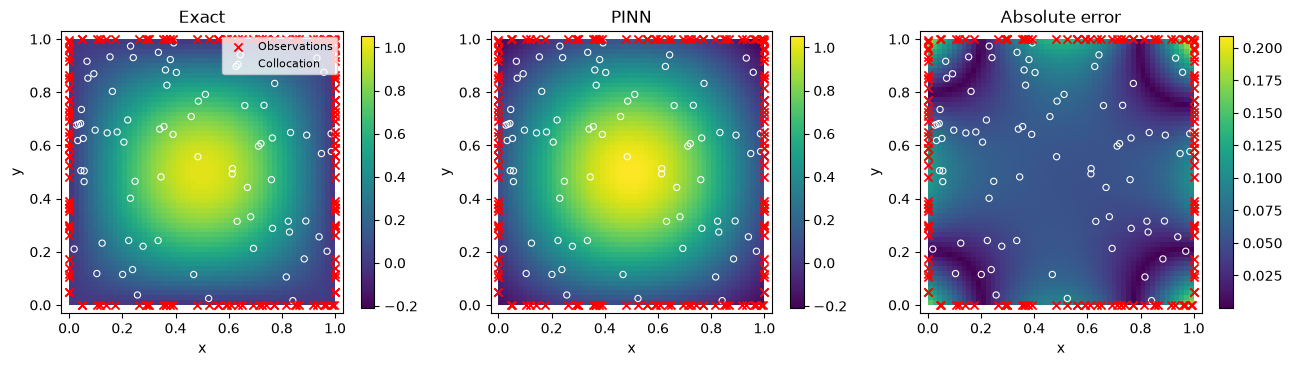

In [41]:
# Representative training points
n_r, n_bc = 80, 40
device = next(poisson.parameters()).device

# Interior collocation points
X_col = torch.rand(n_r, 2, device=device)

# Boundary observations on all four sides
s = torch.rand(n_bc, 1, device=device)
zeros, ones = torch.zeros_like(s), torch.ones_like(s)

X_obs = torch.cat([
    torch.cat([s, zeros], dim=1),  # y = 0
    torch.cat([s, ones], dim=1),   # y = 1
    torch.cat([zeros, s], dim=1),  # x = 0
    torch.cat([ones, s], dim=1)    # x = 1
], dim=0)

obs = X_obs.detach().cpu().numpy()
col = X_col.detach().cpu().numpy()

# Evaluation grid
grid = torch.linspace(0, 1, 55, device=device)
X, Y = torch.meshgrid(grid, grid, indexing="ij")
xy = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)

poisson.eval()
with torch.no_grad():
    exact = poisson_exact(xy).reshape(55, 55).cpu().numpy()
    pred = poisson(xy).reshape(55, 55).cpu().numpy()

# Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, (ax, z, title) in enumerate(zip(
    axes,
    [exact, pred, np.abs(exact - pred)],
    ["Exact", "PINN", "Absolute error"]
)):
    im = ax.imshow(
        z.T, origin="lower", extent=[0, 1, 0, 1],
        aspect="equal", cmap="viridis",
        vmin=min(exact.min(), pred.min()) if i < 2 else None,
        vmax=max(exact.max(), pred.max()) if i < 2 else None
    )

    # Boundary observations
    ax.scatter(
        obs[:, 0], obs[:, 1],
        marker="x", color="red", s=35,
        linewidths=1.3, label="Observations", zorder=5
    )

    # Interior collocation points
    ax.scatter(
        col[:, 0], col[:, 1],
        marker="o", facecolors="none", edgecolors="white",
        s=20, linewidths=0.8, label="Collocation", zorder=4
    )

    ax.set(xlabel="x", ylabel="y", title=title)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    fig.colorbar(im, ax=ax, shrink=0.75)

axes[0].legend(loc="upper right", fontsize=8)

fig.tight_layout()
plt.show()

## 3. Inverse problem: Thermal conductivity identification

We consider:
$$
-k\Delta u(x,y)=q(x,y),\qquad (x,y)\in[0,1]^2
$$

with zero-temperature boundary conditions and a known heat source $q(x,y)$.

The unknowns are now:
$u_\theta(x,y),\qquad k>0$

**Remark:** we must know the physical heat source $q$ independently of $k$. Otherwise, if we only know $f=q/k$, we cannot identify $k$ from the equation $-\Delta u=f$.

In [42]:
### Define the inverse problem

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ground-truth conductivity (only for synthetic data generation)
k_true = 2.5

# Exact manufactured solution
def exact_solution(xy):
    x = xy[:, 0:1]
    y = xy[:, 1:2]
    return torch.sin(torch.pi*x) * torch.sin(torch.pi*y)

# Physical heat source, assumed known during identification.
# Its numerical amplitude is fixed, not recomputed using learned k.
Q = 2 * np.pi**2 * k_true

def heat_source(xy):
    x = xy[:, 0:1]
    y = xy[:, 1:2]
    return Q * torch.sin(torch.pi*x) * torch.sin(torch.pi*y)


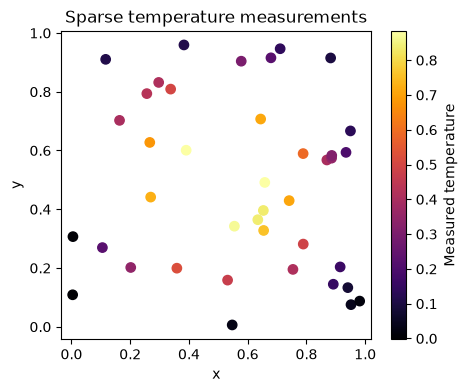

In [43]:
### Generate sparse temperature measurements
torch.manual_seed(42)

N_obs = 40
noise_std = 0.01
xy_obs = torch.rand(N_obs, 2, device=device)

# Generate noisy observations of the exact solution at the observation points
with torch.no_grad():
    u_obs = exact_solution(xy_obs)
    u_obs = u_obs + noise_std * torch.randn_like(u_obs)

plt.figure(figsize=(5, 4))
plt.scatter(
    xy_obs[:, 0].cpu(),
    xy_obs[:, 1].cpu(),
    c=u_obs[:, 0].cpu(),
    cmap="inferno", s=45
)
plt.colorbar(label="Measured temperature")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Sparse temperature measurements")
plt.axis("equal")
plt.show()

In [44]:
### Define the network and the unknown conductivity

class InversePINN(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )

        # Trainable logarithm ensures k > 0
        self.log_k = nn.Parameter(
            torch.tensor(np.log(1.0), dtype=torch.float32)
        )

    @property
    def k(self):
        return torch.exp(self.log_k)

    def forward(self, xy):
        return self.net(xy)

model = InversePINN().to(device)

print("Initial conductivity:", model.k.item())


Initial conductivity: 1.0


In [45]:
# Define the PDE residual


def inverse_pde_residual(model, xy):
    xy = xy.detach().clone().requires_grad_(True)

    u = model(xy)

    grad_u = torch.autograd.grad(
        u, xy,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = grad_u[:, 0:1]
    u_y = grad_u[:, 1:2]

    grad_ux = torch.autograd.grad(
        u_x, xy,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    grad_uy = torch.autograd.grad(
        u_y, xy,
        grad_outputs=torch.ones_like(u_y),
        create_graph=True
    )[0]

    laplacian = grad_ux[:, 0:1] + grad_uy[:, 1:2]

    return -model.k * laplacian - heat_source(xy)

In [46]:
### Define the inverse PINN losses

def sample_boundary(n):
    s = torch.rand(n, 1, device=device)
    edge = torch.randint(0, 4, (n,), device=device)
    xy = torch.cat([s, torch.rand(n, 1, device=device)], dim=1)

    xy[edge == 0, 0] = 0
    xy[edge == 1, 0] = 1
    xy[edge == 2, 1] = 0
    xy[edge == 3, 1] = 1
    return xy

def compute_losses(model, xy_f, xy_b, xy_obs, u_obs):
    # Physics loss: normalize residual by the known source scale
    residual = inverse_pde_residual(model, xy_f)
    loss_pde = (residual / Q).square().mean()

    # Boundary conditions: u = 0
    loss_bc = model(xy_b).square().mean()

    # Measured temperatures
    loss_data = (model(xy_obs) - u_obs).square().mean()

    return loss_pde, loss_bc, loss_data


In [47]:
### Joint training

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 5000
history = {"k": [], "loss": []}

for epoch in range(epochs):
    xy_f = torch.rand(256, 2, device=device)
    xy_b = sample_boundary(128)

    optimizer.zero_grad()

    loss_pde, loss_bc, loss_data = compute_losses(
        model, xy_f, xy_b, xy_obs, u_obs
    )

    loss = loss_pde + 10 * loss_bc + 10 * loss_data
    loss.backward()
    optimizer.step()

    history["k"].append(model.k.item())
    history["loss"].append(loss.item())

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch:4d} | Loss {loss.item():.5f} "
            f"| Estimated k = {model.k.item():.4f}"
        )


Epoch    0 | Loss 2.62657 | Estimated k = 0.9990
Epoch  500 | Loss 0.02695 | Estimated k = 1.9440
Epoch 1000 | Loss 0.00683 | Estimated k = 2.4578
Epoch 1500 | Loss 0.00279 | Estimated k = 2.5017
Epoch 2000 | Loss 0.00165 | Estimated k = 2.5069
Epoch 2500 | Loss 0.00144 | Estimated k = 2.5085
Epoch 3000 | Loss 0.00093 | Estimated k = 2.5099
Epoch 3500 | Loss 0.00150 | Estimated k = 2.5105
Epoch 4000 | Loss 0.00128 | Estimated k = 2.5106
Epoch 4500 | Loss 0.00104 | Estimated k = 2.5108


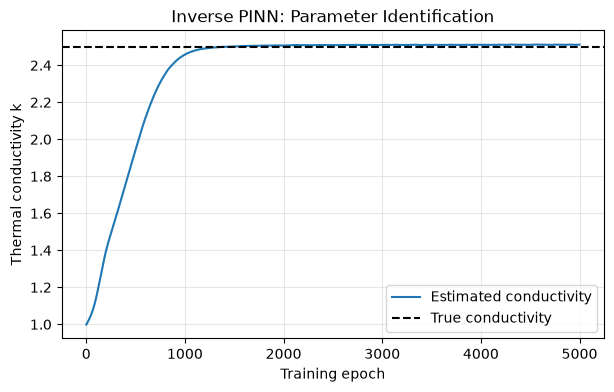

True k:       2.5000
Estimated k:  2.5116
Relative error: 0.46%


In [48]:
### Evaluate parameter identification

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(history["k"], label="Estimated conductivity")
ax.axhline(k_true, linestyle="--", color="black",
           label="True conductivity")

ax.set_xlabel("Training epoch")
ax.set_ylabel("Thermal conductivity k")
ax.set_title("Inverse PINN: Parameter Identification")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print(f"True k:       {k_true:.4f}")
print(f"Estimated k:  {model.k.item():.4f}")
print(f"Relative error: {abs(model.k.item()-k_true)/k_true:.2%}")


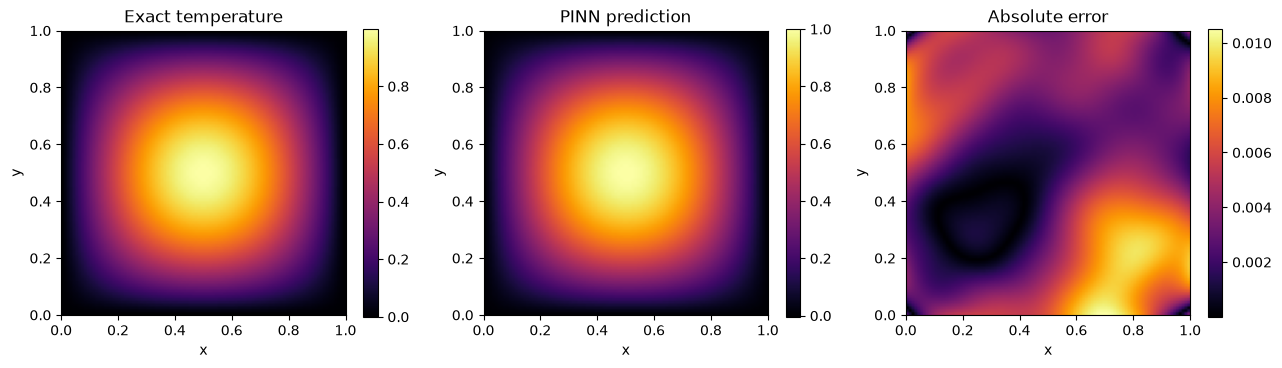

In [49]:
### Compare reconstructed and exact temperature fields

grid_size = 100
x = torch.linspace(0, 1, grid_size, device=device)
y = torch.linspace(0, 1, grid_size, device=device)
X, Y = torch.meshgrid(x, y, indexing="ij")

xy_grid = torch.stack([X.flatten(), Y.flatten()], dim=1)

with torch.no_grad():
    u_pred = model(xy_grid).reshape(grid_size, grid_size)
    u_true = exact_solution(xy_grid).reshape(grid_size, grid_size)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

fields = [
    (u_true, "Exact temperature"),
    (u_pred, "PINN prediction"),
    ((u_pred - u_true).abs(), "Absolute error")
]

for ax, (field, title) in zip(axes, fields):
    img = ax.imshow(
        field.cpu().numpy().T,
        origin="lower", extent=[0, 1, 0, 1],
        cmap="inferno", aspect="equal"
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(img, ax=ax)

plt.tight_layout()
plt.show()


Gauss-Legendre: 10 stages, order 20
Stage times: [0.01043739 0.05397465 0.12823617 0.22664184 0.34045026 0.45954974
 0.57335816 0.67176383 0.74602535 0.78956261]
Epoch 0: loss = 5.526419e-01
Epoch 500: loss = 1.645202e-01
Epoch 1000: loss = 3.119016e-04
Epoch 1500: loss = 1.235891e-04
Epoch 2000: loss = 9.263967e-05


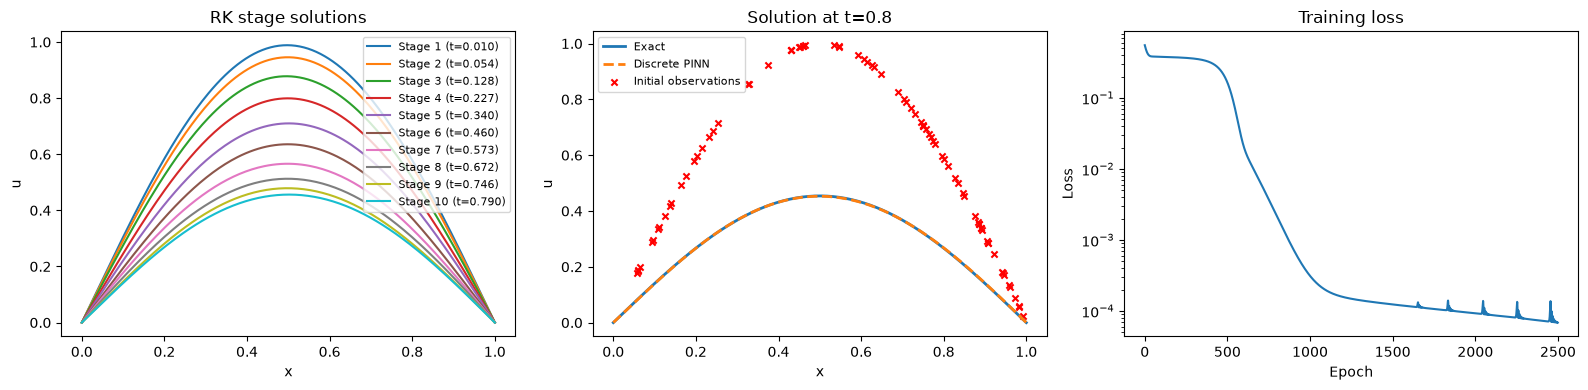

Relative L2 error: 2.534e-03


In [61]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

KAPPA = 0.1
DT = 0.8
Q = 10                  # Number of RK stages (order = 2Q)
N_OBS = 80
EPOCHS = 2500

# -------------------------------------------------------
# 1. Gauss-Legendre Runge-Kutta coefficients
# -------------------------------------------------------
def gauss_legendre_rk(q):
    if q < 1:
        raise ValueError("q must be >= 1")

    nodes, weights = np.polynomial.legendre.leggauss(q)
    c = (nodes + 1) / 2
    b = weights / 2

    # Lagrange basis polynomials evaluated by interpolation
    basis = BarycentricInterpolator(c, np.eye(q))

    A = np.zeros((q, q))
    for i in range(q):
        z = c[i] * (nodes + 1) / 2
        A[i] = (c[i] / 2) * (weights @ basis(z))

    return A, b, c

A_np, b_np, c_np = gauss_legendre_rk(Q)

A = torch.tensor(A_np, dtype=torch.float32, device=device)
b = torch.tensor(b_np, dtype=torch.float32, device=device)

print(f"Gauss-Legendre: {Q} stages, order {2*Q}")
print("Stage times:", DT * c_np)

# -------------------------------------------------------
# 2. Exact solution
# -------------------------------------------------------
def u_exact(t, x):
    t = torch.as_tensor(t, dtype=x.dtype, device=x.device)
    return torch.exp(-KAPPA * np.pi**2 * t) * torch.sin(np.pi * x)

# -------------------------------------------------------
# 3. Neural network: q stages + final solution
# -------------------------------------------------------
class DiscretePINN(nn.Module):
    def __init__(self, q, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, q + 1)
        )

    def forward(self, x):
        return self.net(x)

model = DiscretePINN(Q).to(device)

# Observations at initial time t = 0
x_obs = torch.rand(N_OBS, 1, device=device)
u_obs = u_exact(0.0, x_obs)

# Homogeneous Dirichlet boundaries
x_bc = torch.tensor([[0.], [1.]], device=device)

# -------------------------------------------------------
# 4. Discrete-time PINN loss
# -------------------------------------------------------
def pinn_loss(model=model, x_obs=x_obs, u_obs=u_obs, x_bc=x_bc):
    x = x_obs.detach().clone().requires_grad_(True)

    out = model(x)

    U = out[:, :Q]          # (N, q) RK stages
    Unext = out[:, Q:Q+1]   # (N, 1) solution at t + DT

    # Compute second spatial derivative of every stage
    U_xx = []
    for j in range(Q):
        Uj = U[:, j:j+1]

        Uj_x = torch.autograd.grad(
            Uj, x,
            grad_outputs=torch.ones_like(Uj),
            create_graph=True
        )[0]

        Uj_xx = torch.autograd.grad(
            Uj_x, x,
            grad_outputs=torch.ones_like(Uj_x),
            create_graph=True
        )[0]

        U_xx.append(Uj_xx)

    U_xx = torch.cat(U_xx, dim=1)  # (N, q)

    # Spatial differential operator F(U) = KAPPA * U_xx
    F = KAPPA * U_xx

    # Reconstruct initial solution from all RK stages
    Un_stages = U - DT * (F @ A.T)   # (N, q)

    # Reconstruct initial solution from final output
    Un_final = Unext - DT * (F @ b[:, None])  # (N, 1)

    # All reconstructions must match observed initial data
    reconstructions = torch.cat(
        [Un_stages, Un_final], dim=1
    )  # (N, q+1)

    loss_data = (
        (reconstructions - u_obs)**2
    ).mean()

    # Boundary conditions for all stages and final output
    loss_bc = (model(x_bc)**2).mean()

    return loss_data + 10.0 * loss_bc

# -------------------------------------------------------
# 5. Training
# -------------------------------------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
history = []

for epoch in range(EPOCHS):
    optimizer.zero_grad()
    loss = pinn_loss(model, x_obs, u_obs, x_bc)
    loss.backward()
    optimizer.step()

    history.append(loss.item())

    if epoch % 500 == 0:
        print(f"Epoch {epoch}: loss = {loss.item():.6e}")

# -------------------------------------------------------
# 6. Evaluation and visualization
# -------------------------------------------------------
x_eval = torch.linspace(0, 1, 200, device=device)[:, None]

model.eval()
with torch.no_grad():
    outputs = model(x_eval).cpu().numpy()

x_np = x_eval.cpu().numpy().ravel()
obs_np = x_obs.cpu().numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# RK stage solutions
for j in range(Q):
    t_stage = DT * c_np[j]
    axes[0].plot(
        x_np, outputs[:, j],
        label=f"Stage {j+1} (t={t_stage:.3f})"
    )

axes[0].set(title="RK stage solutions",
            xlabel="x", ylabel="u")
axes[0].legend(fontsize=8)

# Final solution vs ground truth
true = u_exact(DT, x_eval).cpu().numpy().ravel()

axes[1].plot(x_np, true, label="Exact", lw=2)
axes[1].plot(x_np, outputs[:, -1], "--",
             label="Discrete PINN", lw=2)
axes[1].scatter(
    obs_np,
    u_exact(0., x_obs).cpu().numpy().ravel(),
    marker="x", color="red", s=20,
    label="Initial observations"
)
axes[1].set(title=f"Solution at t={DT}",
            xlabel="x", ylabel="u")
axes[1].legend(fontsize=8)

# Training
axes[2].semilogy(history)
axes[2].set(title="Training loss",
            xlabel="Epoch", ylabel="Loss")

plt.tight_layout()
plt.show()

rel_error = np.linalg.norm(outputs[:, -1] - true) / np.linalg.norm(true)
print(f"Relative L2 error: {rel_error:.3e}")

## 5. Causal PINNs: respect the temporal ordering

Return to the 1D heat equation. A standard PINN averages the PDE residual over all times, even when the earliest dynamics are not yet learned.

Partition time into $N_t$ ordered slices. Let $L_i$ be the **mean squared PDE residual** at slice $t_i$:

$$L_i=\frac1{N_x}\sum_j\left|R_\theta(t_i,x_j)\right|^2.$$

A *causal* residual objective uses

$$\boxed{ L_{\rm causal}=\frac1{N_t}\sum_i w_i L_i,\qquad w_i=\exp\!\left(-\varepsilon\sum_{k<i}L_k\right).}$$

**Interpretation:** if early-time losses are large, later-time losses receive small weights. As earlier residuals decrease, the future is gradually admitted. In the weight computation we **detach previous losses**, so the weight acts as a coefficient in each gradient step. A causal PINN still uses **one** continuous neural function $u_\theta(t,x)$. This is a change of loss, not a new time-stepping solver.

In [51]:
def causal_weights(slice_losses, epsilon):
    # cumulative error strictly BEFORE each time index
    earlier = torch.cat([
        torch.zeros(1, device=slice_losses.device),
        torch.cumsum(slice_losses.detach(),dim=0)[:-1]
    ])
    return torch.exp(-epsilon*earlier)

# Inspect the mechanism before training (illustrative residuals).
toy_losses = torch.tensor([0.1, 1.0, 5.0])
for epsilon in (0.5, 5., 20.):
    print(f'epsilon={epsilon:<4}: weights={causal_weights(toy_losses,epsilon).numpy().round(4)}')

epsilon=0.5 : weights=[1.     0.9512 0.5769]
epsilon=5.0 : weights=[1.     0.6065 0.0041]
epsilon=20.0: weights=[1.     0.1353 0.    ]


In [64]:
causal_heat = MLP(2,width=32,depth=3)
NT,NX=10,12
# Increasing epsilon is a continuation schedule: a stricter causal constraint.
epsilon_schedule = [0.1, 1.0, 5.0]
causal_history=[]
weight_snapshots=[]
optimizer=torch.optim.Adam(causal_heat.parameters(),lr=1e-3)

def causal_heat_objective(epsilon):
    # Divide the time domain [0, 1] into NT ordered temporal slices.
    # Each time is repeated NX times to evaluate the PDE at NX spatial points.
    times = torch.linspace(0.0, 1.0, NT).reshape(-1, 1)
    times = times.repeat_interleave(NX, dim=0)

    # Sample independent spatial collocation points for each temporal slice.
    xs = torch.rand(NT * NX, 1)

    # Compute the heat equation residual: u_t - KAPPA * u_xx.
    residual = heat_residual(causal_heat, torch.cat([times, xs], dim=1))

    # Mean squared PDE residual for each temporal slice: shape (NT,).
    slice_losses = (residual.reshape(NT, NX)**2).mean(dim=1)

    # Compute causal weights: later slices receive smaller weights
    # when the PDE residual at earlier times is still large.
    weights = causal_weights(slice_losses, epsilon)

    # Causally weighted PDE loss.
    pde = (weights * slice_losses).mean()

    # Initial condition: u(0, x) = sin(pi*x).
    x0 = torch.rand(64, 1)
    ic = causal_heat(torch.cat([torch.zeros_like(x0), x0], dim=1))
    L_ic = ((ic - torch.sin(PI * x0))**2).mean()

    # Homogeneous Dirichlet boundary conditions:
    # u(t, 0) = 0 and u(t, 1) = 0.
    tb = torch.rand(64, 1)
    bc0 = causal_heat(torch.cat([tb, torch.zeros_like(tb)], dim=1))
    bc1 = causal_heat(torch.cat([tb, torch.ones_like(tb)], dim=1))

    # Total loss: causal PDE residual + initial and boundary constraints.
    # Return causal weights as well to monitor their evolution during training.
    return pde + 10 * L_ic + 10 * ((bc0**2).mean() + (bc1**2).mean()), weights

for epsilon in epsilon_schedule:
    for step in range(750):
        optimizer.zero_grad()
        loss,weights=causal_heat_objective(epsilon)
        loss.backward()
        optimizer.step()
        causal_history.append(float(loss.detach()))
    weight_snapshots.append(weights.detach().numpy().copy())
    print(f'epsilon={epsilon:<4}: loss={causal_history[-1]:.5f}, min weight={weights.min().item():.3f}')

epsilon=0.1 : loss=0.01363, min weight=0.991
epsilon=1.0 : loss=0.00238, min weight=0.982
epsilon=5.0 : loss=0.00275, min weight=0.946


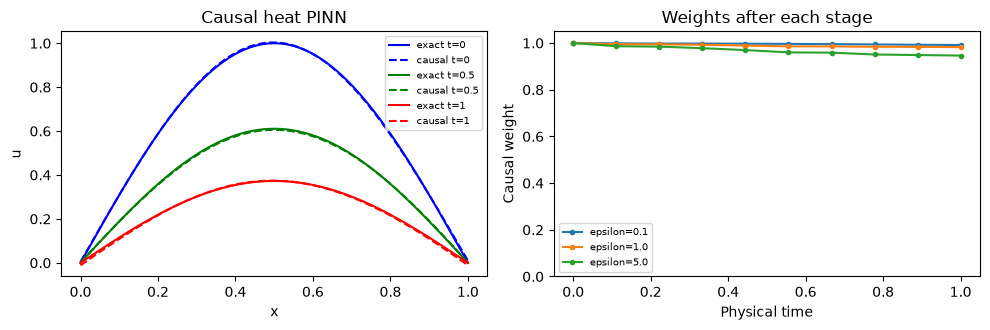

In [65]:
c = ['b', 'g', 'r']
x = torch.linspace(0,1,200).reshape(-1,1)
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
with torch.no_grad():
    for i,time in enumerate((0.,.5,1.)):
        tx=torch.cat([torch.full_like(x,time),x],dim=1)
        axes[0].plot(x.numpy(),heat_exact(tx).numpy(),label=f'exact t={time:g}', color = c[i])
        axes[0].plot(x.numpy(),causal_heat(tx).numpy(),'--',label=f'causal t={time:g}', color = c[i])
for eps,w in zip(epsilon_schedule,weight_snapshots):
    axes[1].plot(np.linspace(0,1,NT),w,marker='.',label=f'epsilon={eps}')
axes[0].set(xlabel='x',ylabel='u',title='Causal heat PINN')
axes[1].set(xlabel='Physical time',ylabel='Causal weight',title='Weights after each stage',ylim=(0,1.05))
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout();plt.show()

### Discussion: what this example does and does not show

The earlier slides explain the **weighting mechanism**; this notebook lets us inspect it numerically. On an easy heat equation, a standard PINN can already work well, so causal training is **not guaranteed to outperform it**. The main benefit may appear in harder long-time, oscillatory, or multiscale dynamics.

**Try:** Van der Pol oscillator, a nonlinear system exhibiting self-sustained oscillations (i.e. it exhibits nonlinear damping, resulting in oscillations with non-sinusoidal trajectories):

$$
\frac{dx}{dt} = y, \qquad
\frac{dy}{dt} = \mu(1-x^2)y-x.
$$

Use $\mu=2,\qquad x(0)=2,\qquad y(0)=0$ over the time interval $t\in[0,20]$.

## 6. Bayesian PINNs: from a single network to a posterior

Consider a scalar ODE describing exponential decay:

$$
u'(t)+\lambda u(t)=0,\qquad u(0)=1,
$$

with exact solution:

$$
u(t)=e^{-\lambda t}.
$$

Assume noisy observations $y_i=u(t_i)+\xi_i$, where $\xi_i\sim\mathcal N(0,\sigma_d^2)$, and an **unknown physical parameter** $\lambda>0$.

Unlike standard PINNs, which estimate a single set of network weights and physical parameters, **Bayesian PINNs infer probability distributions over both**.

Using Bayes' rule:

$$
p(\theta,\lambda\mid D,\mathcal R=0)
\propto
p(D\mid\theta)\,
p(\mathcal R=0\mid\theta,\lambda)\,
p(\theta)\,p(\lambda),
$$

where:

- **Data likelihood:** Measures agreement with noisy observations.
- **Physics likelihood:** Encourages the ODE residual $\mathcal R=u_\theta'+\lambda u_\theta$ to be close to zero.
- **Priors:** Encode assumptions about the network weights and the physical parameter.

### Bayesian inference with Pyro

We use **Pyro** to define the probabilistic model and approximate its posterior through **mean-field variational inference**:

- `pyro.sample()` defines priors and observation likelihoods.
- `AutoDiagonalNormal` constructs a Gaussian variational approximation to the posterior over latent variables (including $\log\lambda$).
- `SVI` optimizes the Evidence Lower Bound (ELBO).

The physics constraint is incorporated as a Gaussian **pseudo-observation** with residual equal to zero and tolerance $\sigma_r$. This tolerance controls the strength of physics enforcement; it does not represent measurement noise.

**Goal:** Obtain a posterior distribution over the solution $u(t)$ and the unknown decay rate $\lambda$, allowing us to quantify uncertainty rather than producing only point estimates.

Remember: 
$$
D_{\mathrm{KL}}
\big(
\mathcal N(\mu,\sigma^2)
\|
\mathcal N(0,\sigma_p^2)
\big)
=
\log\frac{\sigma_p}{\sigma}
+\frac{\sigma^2+\mu^2}{2\sigma_p^2}
-\frac12.
$$

In [54]:
# %pip install pyro-ppl

import pyro
import pyro.distributions as dist

from pyro.infer import SVI, Trace_ELBO
from pyro.infer.autoguide import AutoDiagonalNormal
from pyro.optim import Adam

pyro.set_rng_seed(42)
pyro.clear_param_store()

/Users/franci/miniconda3/envs/sciml/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup and synthetic observations

/var/folders/2_/z19rv3zx4s55k528411fsn800000gn/T/ipykernel_37277/3845621711.py:18: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(t_obs, u_true, "k--", c='b', label="Exact solution")


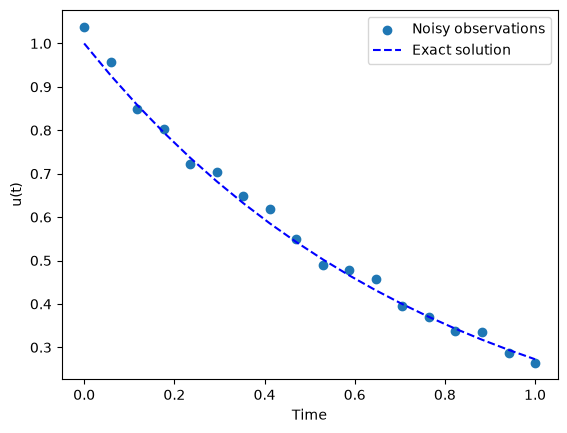

In [55]:
# Physical system
TRUE_LAMBDA = 1.3
SIGMA_DATA = 0.02
SIGMA_PHYS = 0.10
SIGMA_IC = 0.04

# Sparse noisy observations
t_obs = torch.linspace(0, 1, 18).reshape(-1, 1)

u_true = torch.exp(-TRUE_LAMBDA * t_obs)

y_obs = u_true + SIGMA_DATA * torch.randn_like(u_true)

# Physics collocation points (no observations)
t_f = torch.linspace(0, 1, 32).reshape(-1, 1)

plt.scatter(t_obs, y_obs, label="Noisy observations")
plt.plot(t_obs, u_true, "k--", c='b', label="Exact solution")
plt.xlabel("Time")
plt.ylabel("u(t)")
plt.legend()
plt.show()


### Bayesian network and physical model

In [56]:

# Neural network architecture: 1 -> 12 -> 12 -> 1
LAYER_SIZES = [1, 12, 12, 1]


def sample_parameters():
    """Sample one complete neural network and physical parameter."""

    params = []

    for i in range(len(LAYER_SIZES) - 1):
        n_in = LAYER_SIZES[i]
        n_out = LAYER_SIZES[i + 1]

        # Gaussian prior on weights
        W = pyro.sample(
            f"W{i}",
            dist.Normal(
                torch.zeros(n_out, n_in), 1.0
            ).to_event(2)
        )

        # Gaussian prior on biases
        b = pyro.sample(
            f"b{i}",
            dist.Normal(
                torch.zeros(n_out), 1.0
            ).to_event(1)
        )

        params.append((W, b))

    # Log-normal prior on lambda
    log_lambda = pyro.sample(
        "log_lambda",
        dist.Normal(0.0, 0.8)
    )

    lam = torch.exp(log_lambda)

    return params, lam


def neural_forward(t, params):
    """Evaluate one sampled neural network."""

    h = t

    for i, (W, b) in enumerate(params):
        h = F.linear(h, W, b)

        if i < len(params) - 1:
            h = torch.tanh(h)

    return h


Pyro model

In [ ]:
# define the probabilistic model
def model(t_obs, y_obs, t_f):

    # 1. Sample network weights and physical parameter
    params, lam = sample_parameters()

    # 2. Data likelihood
    pred_obs = neural_forward(t_obs, params)

    pyro.sample(
        "observations",
        dist.Normal(
            pred_obs.squeeze(-1), SIGMA_DATA
        ).to_event(1),
        obs=y_obs.squeeze(-1) # with obs returns the log-likelihood of the observations
    )

    # 3. Physics likelihood
    # Need gradients with respect to physical time
    tc = t_f.detach().clone().requires_grad_(True)

    u = neural_forward(tc, params)

    du_dt = torch.autograd.grad(
        u, tc,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    residual = du_dt + lam * u

    pyro.sample(
        "physics",
        dist.Normal(
            residual.squeeze(-1), SIGMA_PHYS
        ).to_event(1),
        obs=torch.zeros_like(residual.squeeze(-1))
    )

    # 4. Initial-condition likelihood
    t0 = torch.zeros(1, 1)
    u0 = neural_forward(t0, params)

    pyro.sample(
        "initial_condition",
        dist.Normal(u0.squeeze(), SIGMA_IC),
        obs=torch.tensor(1.0)
    )


Step    0 | Negative ELBO: 8477.240
Step  300 | Negative ELBO: 952.976
Step  600 | Negative ELBO: 1726.350
Step  900 | Negative ELBO: 1083.729
Step 1200 | Negative ELBO: 959.411
Step 1500 | Negative ELBO: 999.940
Step 1800 | Negative ELBO: 738.404
Step 2100 | Negative ELBO: 630.485
Step 2400 | Negative ELBO: 708.590
Step 2700 | Negative ELBO: 1059.965
Step 3000 | Negative ELBO: 1019.936
Step 3300 | Negative ELBO: 667.163
Step 3600 | Negative ELBO: 462.345
Step 3900 | Negative ELBO: 643.079
Step 4200 | Negative ELBO: 442.042
Step 4500 | Negative ELBO: 562.267
Step 4800 | Negative ELBO: 404.884
Step 5100 | Negative ELBO: 439.648
Step 5400 | Negative ELBO: 601.904
Step 5700 | Negative ELBO: 389.762
Step 6000 | Negative ELBO: 505.633
Step 6300 | Negative ELBO: 344.021
Step 6600 | Negative ELBO: 412.570
Step 6900 | Negative ELBO: 443.418
Step 7200 | Negative ELBO: 433.136
Step 7500 | Negative ELBO: 338.944
Step 7800 | Negative ELBO: 495.748
Step 8100 | Negative ELBO: 425.711
Step 8400 | Neg

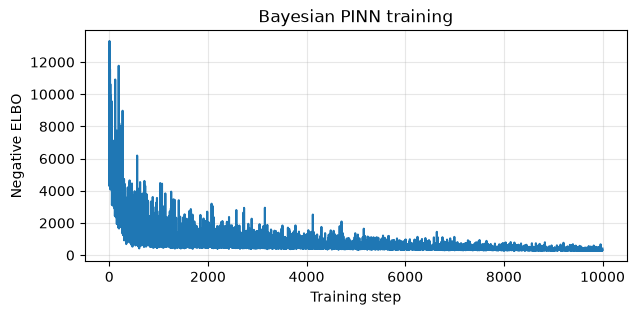

In [58]:
# Automatically constructs a variational distribution to approximate the posterior over the model’s latent variables
guide = AutoDiagonalNormal(model)  

optimizer = Adam({"lr": 0.0005})

# SVI (Stochastic Variational Inference) optimizes the guide's parameters by minimizing the negative ELBO, balancing data fitting, physical consistency, and regularization toward the priors.
svi = SVI(
    model,
    guide,
    optimizer,
    loss=Trace_ELBO(num_particles=2)
)

loss_history = []

N_STEPS = 10000

for step in range(N_STEPS):

    loss = svi.step(t_obs, y_obs, t_f)

    loss_history.append(loss)

    if step % 300 == 0:
        print(f"Step {step:4d} | Negative ELBO: {loss:.3f}")

plt.figure(figsize=(7, 3))
plt.plot(loss_history)
plt.xlabel("Training step")
plt.ylabel("Negative ELBO")
plt.title("Bayesian PINN training")
plt.grid(alpha=0.3)
plt.show()


Posterior predictions

In [59]:
t_test = torch.linspace(0, 1, 200).reshape(-1, 1)

N_SAMPLES = 200

curves = []
lambdas = []

with torch.no_grad():
    for _ in range(N_SAMPLES):

        # Sample all latent variables from the variational posterior
        sample = guide(t_obs, y_obs, t_f)

        params = [
            (sample[f"W{i}"], sample[f"b{i}"])
            for i in range(len(LAYER_SIZES) - 1)
        ]

        lam = torch.exp(sample["log_lambda"])

        prediction = neural_forward(t_test, params)

        curves.append(prediction.squeeze(-1).numpy())
        lambdas.append(lam.item())

curves = np.stack(curves)
lambdas = np.array(lambdas)

mean = curves.mean(axis=0)
low, high = np.percentile(curves, [2.5, 97.5], axis=0)


Posterior uncertainty

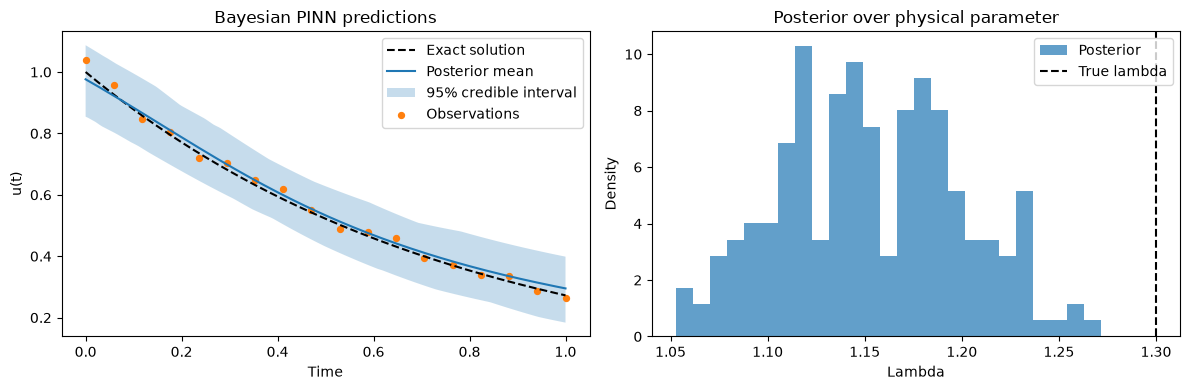

True lambda: 1.3
Posterior mean: 1.1535709172487258
95% interval: [1.07281833 1.23595241]


In [60]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

t_np = t_test.squeeze(-1).numpy()

# Posterior predictive distribution of latent solution
axes[0].plot(
    t_np,
    np.exp(-TRUE_LAMBDA * t_np),
    "k--",
    label="Exact solution"
)

axes[0].plot(
    t_np, mean,
    label="Posterior mean"
)

axes[0].fill_between(
    t_np, low, high,
    alpha=0.25,
    label="95% credible interval"
)

axes[0].scatter(
    t_obs.squeeze().numpy(),
    y_obs.squeeze().numpy(),
    s=18,
    label="Observations"
)

axes[0].set(
    xlabel="Time",
    ylabel="u(t)",
    title="Bayesian PINN predictions"
)
axes[0].legend()

# Posterior distribution of lambda
axes[1].hist(
    lambdas,
    bins=25,
    density=True,
    alpha=0.7,
    label="Posterior"
)

axes[1].axvline(
    TRUE_LAMBDA,
    color="black",
    linestyle="--",
    label="True lambda"
)

axes[1].set(
    xlabel="Lambda",
    ylabel="Density",
    title="Posterior over physical parameter"
)
axes[1].legend()

plt.tight_layout()
plt.show()

print("True lambda:", TRUE_LAMBDA)
print("Posterior mean:", lambdas.mean())
print("95% interval:", np.percentile(lambdas, [2.5, 97.5]))
